In [1]:
import os, sys, json, re, random, unicodedata, copy, time, hashlib, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfTransformer

import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset

# Có thể đặt biến môi trường để thay đổi cấu hình trước khi chạy notebook.
SEED = int(os.environ.get('DSS_SEED', '42'))
ENCODER_EPOCHS = int(os.environ.get('DSS_ENCODER_EPOCHS', '40'))
BATCH_SIZE = int(os.environ.get('DSS_BATCH_SIZE', '128'))
if min(ENCODER_EPOCHS, BATCH_SIZE) < 1:
    raise ValueError('Số vòng huấn luyện và kích thước batch phải lớn hơn 0.')

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def find_input(filename, env_name):
    explicit = os.environ.get(env_name)
    if explicit:
        path = Path(explicit).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'{env_name} không trỏ tới tệp hợp lệ: {path}')
        return path.resolve()
    for path in (Path.cwd() / 'data' / filename, Path.cwd() / filename):
        if path.is_file():
            return path.resolve()
    kaggle_input = Path('/kaggle/input')
    found = sorted(kaggle_input.rglob(filename)) if kaggle_input.exists() else []
    if len(found) == 1:
        return found[0].resolve()
    if len(found) > 1:
        raise ValueError(f'Có nhiều tệp {filename}; hãy đặt {env_name} để chọn một tệp.')
    raise FileNotFoundError(f'Không tìm thấy {filename}; hãy đặt {env_name}.')

DATA_PATH = find_input('dish_knowledge_base_with_images.json', 'DSS_DATA_PATH')
SYN_PATH = find_input('ingredients_synonyms_qwen.json', 'DSS_SYNONYMS_PATH')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
base = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path.cwd()
OUTPUT_DIR = Path(os.environ.get('DSS_OUTPUT_DIR', str(base / 'training_runs' / RUN_ID))).expanduser()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
protected_names = ['ingredient_set_encoder.pt', 'knowledge_graph.json',
                   'metrics.json', 'model_comparison.csv', 'model_comparison_charts.png',
                   'run_manifest.json', 'splits.json']
existing = [name for name in protected_names if (OUTPUT_DIR / name).exists()]
if existing:
    raise FileExistsError(f'Thư mục đầu ra đã có tệp {existing}; hãy chọn thư mục trống bằng DSS_OUTPUT_DIR.')

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

print(f'Môi trường: {DEVICE}; seed: {SEED}')
print(f'Dữ liệu món ăn: {DATA_PATH}')
print(f'Từ điển đồng nghĩa: {SYN_PATH}')
print(f'Thư mục kết quả riêng: {OUTPUT_DIR.resolve()}')

Môi trường: cuda; seed: 42
Dữ liệu món ăn: /kaggle/input/datasets/phanchuc123/train304/dish_knowledge_base_with_images.json
Từ điển đồng nghĩa: /kaggle/input/datasets/phanchuc123/train304/ingredients_synonyms_qwen.json
Thư mục kết quả riêng: /kaggle/working/training_runs/20261124T044511397310Z


In [2]:
def normalize(value):
    s = unicodedata.normalize('NFKC', str(value or '')).lower().strip().replace('\u0111', 'd')
    s = ''.join(c for c in unicodedata.normalize('NFD', s) if unicodedata.category(c) != 'Mn')
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]+', ' ', s)).strip()

# 1. Từ điển từ đồng nghĩa thực phẩm tiếng Việt chuẩn
FOOD_SYNONYMS = {
    # Thịt heo và các phần thịt có cùng tên gọi.
    'thit lon': 'thit heo',
    'thit ba chi': 'ba chi', 'thit ba chi heo': 'ba chi',
    'thit ba chi lon': 'ba chi', 'ba chi heo': 'ba chi', 'ba chi lon': 'ba chi',
    'ba roi': 'ba chi', 'thit ba roi': 'ba chi',
    'thit ba roi heo': 'ba chi', 'thit ba roi lon': 'ba chi',
    'thit lon xay': 'thit heo xay', 'thit lon bam': 'thit heo bam',
    'suon lon': 'suon heo', 'gio lon': 'gio heo',
    'chan gio lon': 'gio heo', 'chan gio heo': 'gio heo',
    'da lon': 'da heo', 'bi lon': 'da heo', 'bi heo': 'da heo',
    'gan lon': 'gan heo', 'tim lon': 'tim heo', 'mo lon': 'mo heo',

    # Quy tắc đã có: các loại trứng được gộp về tên chung.
    'trung ga': 'trung', 'trung vit': 'trung', 'qua trung': 'trung',

    # Rau củ, trái cây và cách gọi vùng miền.
    'dua chuot': 'dua leo', 'qua dua chuot': 'dua leo', 'qua dua leo': 'dua leo',
    'khom': 'thom', 'trai khom': 'thom', 'qua khom': 'thom', 'trai thom': 'thom',
    'chanh leo': 'chanh day', 'qua chanh leo': 'chanh day',
    'trai chanh leo': 'chanh day', 'qua chanh day': 'chanh day',
    'quat': 'tac', 'qua quat': 'tac', 'trai tac': 'tac', 'qua tac': 'tac',
    'muop dang': 'kho qua', 'trai kho qua': 'kho qua', 'qua kho qua': 'kho qua',
    'bi ngo': 'bi do', 'qua bi ngo': 'bi do', 'trai bi do': 'bi do', 'qua bi do': 'bi do',
    'cai bap': 'bap cai', 'rau bap cai': 'bap cai', 'cai bap tim': 'bap cai tim',
    'bap cai thao': 'cai thao',
    'sup lo xanh': 'bong cai xanh', 'cai bong xanh': 'bong cai xanh',
    'sup lo trang': 'bong cai trang', 'cai bong trang': 'bong cai trang',
    'rau bina': 'cai bo xoi', 'rau chan vit': 'cai bo xoi', 'chan vit': 'cai bo xoi',
    'hoa chuoi': 'bap chuoi', 'bong chuoi': 'bap chuoi',
    'trai ca tim': 'ca tim', 'qua ca tim': 'ca tim',
    'qua ca chua': 'ca chua', 'trai ca chua': 'ca chua',
    'cu ca rot': 'ca rot', 'cu khoai tay': 'khoai tay', 'cu su hao': 'su hao',

    # Các loại rau thơm: giữ riêng từng loại.
    'rau ngo': 'ngo om', 'rau mui': 'ngo ri',
    'mui tau': 'ngo gai', 'rau mui tau': 'ngo gai', 'rau ngo gai': 'ngo gai',
    'rau om': 'ngo om', 'rau ngo om': 'ngo om',
    'rau que': 'hung que', 'rau hung que': 'hung que', 'la hung que': 'hung que',
    'rau kinh gioi': 'kinh gioi', 'la kinh gioi': 'kinh gioi',
    'rau tia to': 'tia to', 'la tia to': 'tia to',
    'rau giap ca': 'rau diep ca', 'giap ca': 'rau diep ca', 'diep ca': 'rau diep ca',
    'hanh hoa': 'hanh la', 'hanh xanh': 'hanh la',
    'hanh kho': 'hanh tim', 'hanh cu': 'hanh tim', 'hanh tim bam': 'hanh tim',
    'hanh huong': 'hanh tim', 'cu hanh tay': 'hanh tay',
    'bo ro': 'toi tay', 'hanh bo ro': 'toi tay', 'hanh paro': 'toi tay',

    # Nấm: không gộp nấm tươi/khô hay các loài khác nhau.
    'moc nhi': 'nam meo', 'nam moc nhi': 'nam meo',
    'nam dong co': 'nam huong', 'nam shiitake': 'nam huong',
    'nam so': 'nam bao ngu', 'nam enoki': 'nam kim cham',

    # Đậu, hạt và bột.
    'dau phong': 'lac', 'hat dau phong': 'lac', 'hat lac': 'lac',
    'dau phu': 'dau hu', 'tau hu': 'dau hu', 'tofu': 'dau hu',
    'dau tuong': 'dau nanh', 'hat dau tuong': 'dau nanh', 'hat dau nanh': 'dau nanh',
    'gao no': 'gao nep', 'bot gao nep': 'bot nep',
    'ngo': 'bap',

    # Gia vị, thực phẩm chế biến và đồ uống.
    'xi dau': 'nuoc tuong', 'soy sauce': 'nuoc tuong',
    'dau vung': 'dau me', 'dau hat vung': 'dau me', 'dau hat me': 'dau me',
    'dam': 'giam', 'dam an': 'giam', 'giam an': 'giam',
    'bot vi tinh': 'bot ngot',
    'phomai': 'pho mai', 'pho mat': 'pho mai', 'phomat': 'pho mai',
    'yaourt': 'sua chua', 'yogurt': 'sua chua', 'da ua': 'sua chua',
    'bo khong muoi': 'bo lat',

    # Tên vùng miền của một số loại cá.
    'ca qua': 'ca loc', 'ca chuoi': 'ca loc', 'ca ba sa': 'ca basa',
}

# 2. Quy đổi các biến thể gia vị (khắc phục lỗi tiêu vs tiêu xay, muối hạt vs muối tinh...)
SPICE_EXPANSIONS = {
    # Tiêu: giữ quy tắc cũ gộp tiêu đen, tiêu trắng và tiêu sọ về tiêu.
    'tieu xay': 'tieu', 'tieu bot': 'tieu', 'tieu den': 'tieu', 'tieu den xay': 'tieu',
    'hat tieu': 'tieu', 'hat tieu xay': 'tieu', 'tieu hat': 'tieu', 'tieu trang': 'tieu',
    'tieu trang xay': 'tieu', 'tieu so': 'tieu', 'tieu so xay': 'tieu',
    'hat tieu den': 'tieu', 'hat tieu trang': 'tieu', 'hat tieu so': 'tieu',
    'tieu hat den': 'tieu', 'tieu hat trang': 'tieu', 'bot tieu': 'tieu',
    'bot tieu den': 'tieu', 'bot tieu trang': 'tieu', 'tieu xay nhuyen': 'tieu',
    'hat tieu den xay': 'tieu', 'hat tieu trang xay': 'tieu',
    'ground black pepper': 'tieu',

    # Muối ăn; không gộp các hỗn hợp như muối ớt, muối tiêu.
    'muoi tinh': 'muoi', 'muoi hat': 'muoi', 'muoi iot': 'muoi', 'muoi bot': 'muoi',
    'muoi an': 'muoi', 'muoi hot': 'muoi', 'muoi nau an': 'muoi', 'muoi trang': 'muoi',
    'muoi an iot': 'muoi', 'muoi i ot': 'muoi',

    # Đường trắng; giữ riêng đường nâu, đường phèn và đường thốt nốt.
    'duong cat': 'duong', 'duong trang': 'duong', 'duong cat trang': 'duong',
    'duong tinh luyen': 'duong', 'duong kinh': 'duong', 'duong kinh trang': 'duong',
    'duong cat tinh luyen': 'duong', 'duong trang tinh luyen': 'duong',

    # Tỏi và hành tím: giữ lại cả các quy tắc đã có từ trước.
    'toi bam': 'toi', 'cu toi': 'toi', 'toi phi': 'toi', 'toi tuoi': 'toi',
    'tep toi': 'toi', 'toi cu': 'toi', 'toi xay': 'toi', 'toi bam nhuyen': 'toi',
    'toi boc vo': 'toi',
    'hanh kho': 'hanh tim', 'hanh cu': 'hanh tim', 'hanh tim bam': 'hanh tim',
    'cu hanh tim': 'hanh tim', 'hanh huong': 'hanh tim', 'hanh tim tuoi': 'hanh tim',
    'hanh tim boc vo': 'hanh tim', 'hanh tim xay': 'hanh tim',

    # Nước mắm và dầu ăn; không gộp nước mắm chay hay dầu mè.
    'nuoc mam ngon': 'nuoc mam', 'nuoc mam truyen thong': 'nuoc mam',
    'nuoc mam nguyen chat': 'nuoc mam', 'nuoc mam nhi': 'nuoc mam',
    'dau thuc vat': 'dau an', 'dau nau an': 'dau an', 'dau an thuc vat': 'dau an',
    'dau thuc vat nau an': 'dau an', 'vegetable oil': 'dau an',

    # Ớt tươi, bột ngọt và nước uống.
    'ot hiem': 'ot', 'ot trai': 'ot', 'ot sung': 'ot', 'ot tuoi': 'ot',
    'trai ot': 'ot', 'qua ot': 'ot', 'ot bam': 'ot',
    'mi chinh': 'bot ngot', 'bot vi tinh': 'bot ngot', 'msg': 'bot ngot',
    'monosodium glutamate': 'bot ngot',
    'nuoc tinh khiet': 'nuoc loc', 'nuoc uong': 'nuoc loc',

    # Các loại nước sốt và gia vị khác; mỗi loại có tên chuẩn riêng.
    'xi dau': 'nuoc tuong', 'soy sauce': 'nuoc tuong', 'nuoc tuong xi dau': 'nuoc tuong',
    'dam': 'giam', 'dam an': 'giam', 'giam an': 'giam', 'vinegar': 'giam',
    'oyster sauce': 'dau hao', 'sot dau hao': 'dau hao',
    'chili sauce': 'tuong ot', 'tuong ot cay': 'tuong ot',
    'ketchup': 'tuong ca', 'tuong ca ketchup': 'tuong ca',
    'bot canh nau an': 'bot canh', 'bot nem gia vi': 'bot nem',
}

synonym_to_canonical = dict(FOOD_SYNONYMS)
synonym_to_canonical.update(SPICE_EXPANSIONS)

if Path(SYN_PATH).exists():
    with open(SYN_PATH, 'r', encoding='utf-8') as f:
        syn_data = json.load(f)
    for item in syn_data:
        raw_ing = normalize(item.get('ingredient', ''))
        for syn in item.get('synonyms', []):
            s = normalize(syn)
            if not s or s == raw_ing: continue
            # Lọc bỏ hallucination của LLM (nước -> muối nở, vani...)
            if s in ('muoi no', 'bot no', 'vani nuoc') and not any(w in raw_ing for w in ('no', 'baking', 'vani')):
                continue
            if s in ('top mo hanh phi', 'nguyen lieu nuoc cham', 'ot chanh tac rau an kem'):
                continue
            if s in raw_ing or set(s.split()).issubset(set(raw_ing.split())):
                synonym_to_canonical[raw_ing] = s

# Tên chuẩn trong bảng thủ công không bị đề xuất tự động đổi sang tên khác.
# Các quy tắc thủ công được ưu tiên sau Qwen, rồi áp dụng gia vị như app.py.
for canonical in set(FOOD_SYNONYMS.values()) | set(SPICE_EXPANSIONS.values()):
    if canonical not in FOOD_SYNONYMS and canonical not in SPICE_EXPANSIONS:
        synonym_to_canonical.pop(canonical, None)
synonym_to_canonical.update(FOOD_SYNONYMS)
synonym_to_canonical.update(SPICE_EXPANSIONS)
print(f'✓ Đã xây dựng {len(synonym_to_canonical)} quy tắc ánh xạ từ đồng nghĩa.')

# Tập gia vị tủ bếp mặc định (Default Pantry Staples)
DEFAULT_PANTRY = {
    # Gia vị cơ bản.
    'muoi', 'muoi tinh', 'muoi hat', 'muoi iot', 'muoi bot',
    'duong', 'duong trang', 'duong cat', 'duong cat trang',
    'tieu', 'tieu xay', 'tieu bot', 'tieu den', 'tieu den xay',
    'hat tieu', 'hat tieu xay', 'tieu trang', 'tieu so',
    'toi', 'toi bam', 'cu toi', 'hanh', 'hanh tim', 'hanh kho', 'hanh cu',
    'ot', 'ot trai', 'ot bot', 'ot hiem',
    'hat nem', 'bot ngot', 'bot nem ga', 'mi chinh', 'bot canh', 'bot nem',

    # Nước, dầu và nước sốt thường dùng. Đây là các nguyên liệu được giả định sẵn có.
    'nuoc loc', 'nuoc', 'da vien', 'nuoc mam', 'nuoc mam ngon',
    'dau an', 'dau thuc vat', 'nuoc tuong', 'giam', 'dau hao', 'tuong ot', 'tuong ca',
}

# Web bổ sung các biến thể gia vị vào tập tủ bếp mặc định.
DEFAULT_PANTRY.update(SPICE_EXPANSIONS.keys())
# Công thức được lưu theo tên chuẩn, nên bổ sung cả tên chuẩn vào tủ bếp.
DEFAULT_PANTRY.update(SPICE_EXPANSIONS.values())

# Đọc và chuẩn hóa dữ liệu món ăn
with open(DATA_PATH, encoding='utf-8') as f: raw = json.load(f)
recipes, names = [], {}
for dish in raw:
    items = {}
    for ing in dish.get('ingredients', []):
        name = ing.get('name_vi', '')
        key = normalize(name)
        key = synonym_to_canonical.get(key, key) # Ánh xạ từ chuẩn
        if not key or not re.search('[a-z]', key): continue
        try: weight = float(ing.get('importance') or 1)
        except (ValueError, TypeError): weight = 1.0
        weight = min(3., max(1., weight))
        items[key] = max(items.get(key, 0), weight)
        names.setdefault(key, name)
    if len(items) >= 2:
        recipes.append({
            'id': dish.get('id'), 'name': dish.get('name_vi', ''), 'ingredients': items,
            'category': dish.get('category'), 'url': dish.get('url'), 'image_url': dish.get('image_url')
        })

vocab = {key: i + 1 for i, key in enumerate(sorted(names))} # 0 = padding
keys = [None] + sorted(names)
print(f"✓ Công thức hợp lệ: {len(recipes)} | Số nguyên liệu sau chuẩn hóa: {len(vocab)}")

weights = np.zeros((len(recipes), len(vocab)+1), dtype=np.float32)
for i, dish in enumerate(recipes):
    for key, w in dish['ingredients'].items(): weights[i, vocab[key]] = w
row_sums = np.maximum(weights.sum(axis=1), 1e-8)
recipe_ids = [np.flatnonzero(row).tolist() for row in weights]
bin_weights = (weights > 0).astype(np.float32)


✓ Đã xây dựng 1091 quy tắc ánh xạ từ đồng nghĩa.
✓ Công thức hợp lệ: 3253 | Số nguyên liệu sau chuẩn hóa: 3502


In [3]:
# Sinh tập truy vấn nhân tạo (Synthetic Queries) có thêm nhiễu thực tế
TRAIN_PER_DISH, VAL_PER_DISH, TEST_PER_DISH = 8, 2, 2
rng = random.Random(SEED)
splits = {'train': [], 'val': [], 'test': []}
all_ids = list(range(1, len(vocab)+1))

for label, ids in enumerate(recipe_ids):
    seen, generated = set(), []
    outside = sorted(set(all_ids) - set(ids))  # thứ tự ổn định cho cùng seed
    for _ in range(120):
        n_keep = rng.randint(1, len(ids)-1)
        query = rng.sample(ids, n_keep)
        if outside and rng.random() < 0.35:
            query += rng.sample(outside, min(len(outside), rng.randint(1, 2)))
        q = tuple(sorted(set(query)))
        if q not in seen:
            seen.add(q); generated.append((q, label))
        if len(generated) >= TRAIN_PER_DISH + VAL_PER_DISH + TEST_PER_DISH: break
    rng.shuffle(generated)
    splits['test'].extend(generated[:min(TEST_PER_DISH, max(0, len(generated)-1))])
    remain = generated[min(TEST_PER_DISH, max(0, len(generated)-1)):]
    nval = min(VAL_PER_DISH, max(0, len(remain)-1))
    splits['val'].extend(remain[:nval]); splits['train'].extend(remain[nval:])

for k, v in splits.items(): print(f"Tập {k}: {len(v)} mẫu")

class Queries(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(batch):
    lengths = max(len(q) for q, _ in batch)
    x = torch.zeros((len(batch), lengths), dtype=torch.long)
    for i, (q, _) in enumerate(batch): x[i, :len(q)] = torch.tensor(q)
    return x, torch.tensor([y for _, y in batch], dtype=torch.long)

train_loader = DataLoader(Queries(splits['train']), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(Queries(splits['val']), batch_size=BATCH_SIZE, collate_fn=collate)
test_loader = DataLoader(Queries(splits['test']), batch_size=BATCH_SIZE, collate_fn=collate)


Tập train: 26024 mẫu
Tập val: 6506 mẫu
Tập test: 6506 mẫu


In [4]:
class IngredientSetEncoder(nn.Module):
    def __init__(self, n_ing, n_recipes, dim=96, hidden=192, dropout=0.2):
        super().__init__()
        self.embedding = nn.Embedding(n_ing + 1, dim, padding_idx=0)
        self.net = nn.Sequential(
            nn.Linear(dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, n_recipes)
        )
    def forward(self, x):
        mask = (x != 0).unsqueeze(-1)
        pooled = (self.embedding(x) * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.net(pooled)

EPOCHS, LR, PATIENCE = ENCODER_EPOCHS, 0.001, 4
model = IngredientSetEncoder(len(vocab), len(recipes)).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
loss_fn = nn.CrossEntropyLoss()
best_loss, best_state, stale = float('inf'), None, 0

train_loss_history = []
val_loss_history = []

print("=== BẮT ĐẦU HUẤN LUYỆN INGREDIENT SET ENCODER ===")
for epoch in range(1, EPOCHS+1):
    model.train(); total = count = 0
    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
        total += loss.item()*len(y); count += len(y)
    
    model.eval(); val_total = val_count = 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            val_total += loss_fn(model(x), y).item()*len(y); val_count += len(y)
            
    tl = total / count; vl = val_total / val_count
    train_loss_history.append(tl); val_loss_history.append(vl)
    print(f"Epoch {epoch:02d} | Train Loss: {tl:.4f} | Val Loss: {vl:.4f}")
    
    if vl < best_loss - 1e-4:
        best_loss, best_state, stale = vl, copy.deepcopy(model.state_dict()), 0
    else:
        stale += 1
        if stale >= PATIENCE:
            print(f"-> Early stopping tại epoch {epoch} (Best Val Loss: {best_loss:.4f})")
            break

model.load_state_dict(best_state)


=== BẮT ĐẦU HUẤN LUYỆN INGREDIENT SET ENCODER ===
Epoch 01 | Train Loss: 7.7948 | Val Loss: 6.8154
Epoch 02 | Train Loss: 5.0432 | Val Loss: 4.5524
Epoch 03 | Train Loss: 2.9708 | Val Loss: 3.7084
Epoch 04 | Train Loss: 2.1398 | Val Loss: 3.3801
Epoch 05 | Train Loss: 1.7101 | Val Loss: 3.2101
Epoch 06 | Train Loss: 1.4450 | Val Loss: 3.1290
Epoch 07 | Train Loss: 1.2684 | Val Loss: 3.1049
Epoch 08 | Train Loss: 1.1327 | Val Loss: 3.0824
Epoch 09 | Train Loss: 1.0363 | Val Loss: 3.0905
Epoch 10 | Train Loss: 0.9697 | Val Loss: 3.0938
Epoch 11 | Train Loss: 0.9069 | Val Loss: 3.1100
Epoch 12 | Train Loss: 0.8513 | Val Loss: 3.1218
-> Early stopping tại epoch 12 (Best Val Loss: 3.0824)


<All keys matched successfully>

In [6]:
def features_batch(x):
    present = np.zeros((len(x), len(vocab)+1), dtype=np.float32)
    for i, row in enumerate(x.cpu().numpy()): present[i, row[row != 0]] = 1
    matched = present @ (weights > 0).astype(np.float32).T
    coverage = matched / np.maximum(present.sum(axis=1, keepdims=True), 1)
    cbf = (present @ weights.T) / row_sums[None, :]
    main = ((weights > 0) & (weights == weights.max(axis=1, keepdims=True))).astype(np.float32)
    main_count = main.sum(axis=1)
    main_score = np.divide(present @ main.T, main_count[None, :],
                           out=np.ones((len(x), len(recipes)), dtype=np.float32),
                           where=main_count[None, :] > 0)
    with torch.no_grad(): logits = model(x.to(DEVICE)).cpu().numpy()
    lo, hi = logits.min(axis=1, keepdims=True), logits.max(axis=1, keepdims=True)
    deep = (logits-lo) / np.maximum(hi-lo, 1e-8)
    return deep, cbf, coverage, main_score, matched

def collect_features(loader):
    model.eval(); feature_parts = []; labels = []
    for x, y in loader:
        feature_parts.append(features_batch(x)); labels.append(y.numpy())
    return tuple(np.concatenate([part[i] for part in feature_parts]) for i in range(5)), np.concatenate(labels)

def compute_metrics(scores, matched, labels):
    scores = np.where(matched > 0, scores, -np.inf)
    ranking = np.argsort(-scores, axis=1)[:, :10]
    
    hits = {f'Hit@{k}': round(float((ranking[:, :k] == labels[:, None]).any(axis=1).mean()), 4) for k in (1, 5, 10)}
    # Mean Reciprocal Rank (MRR)
    matches = (ranking == labels[:, None])
    reciprocal_ranks = np.zeros(len(labels))
    for i in range(len(labels)):
        nz = np.flatnonzero(matches[i])
        if len(nz) > 0:
            reciprocal_ranks[i] = 1.0 / (nz[0] + 1)
    hits['MRR'] = round(float(reciprocal_ranks.mean()), 4)  # MRR@10
    return hits

def evaluate_features(features, labels, coeff):
    deep, cbf, coverage, main, matched = features
    scores = coeff[0]*deep + coeff[1]*cbf + coeff[2]*coverage + coeff[3]*main
    return compute_metrics(scores, matched, labels)

# 1. Tìm trọng số tối ưu trên Validation Set
val_features, val_labels = collect_features(val_loader)
candidates = [(a/4, b/4, c/4, (4-a-b-c)/4) for a in range(1, 5) for b in range(5-a) for c in range(5-a-b)]
validation_grid = [(evaluate_features(val_features, val_labels, c)['Hit@10'], c) for c in candidates]
best_score, best_coeff = max(validation_grid, key=lambda t: t[0])
print(f"✓ Trọng số tối ưu Deep Hybrid: {best_coeff} (Hit@10 Val: {best_score:.4f})")

# 2. Đánh giá tất cả các mô hình trên cùng Test Set
test_features, test_labels = collect_features(test_loader)
deep, cbf, coverage, main, matched = test_features

# TF-IDF & Jaccard Baselines
tfidf_trans = TfidfTransformer(norm='l2')
recipe_tfidf = tfidf_trans.fit_transform(bin_weights).toarray()

test_queries = [row[row != 0] for x, _ in test_loader for row in x.cpu().numpy()]
N_test = len(test_queries)
Q_mat = np.zeros((N_test, len(vocab)+1), dtype=np.float32)
for i, q in enumerate(test_queries): Q_mat[i, q] = 1.0

# Batching to compute Jaccard & TF-IDF
CHUNK = 1000
jaccard_all = []; tfidf_all = []
d_lens = bin_weights.sum(axis=1, keepdims=True).T
for start in range(0, N_test, CHUNK):
    end = min(start + CHUNK, N_test)
    sub_q = Q_mat[start:end]
    sub_inter = sub_q @ bin_weights.T
    sub_union = sub_q.sum(axis=1, keepdims=True) + d_lens - sub_inter
    jaccard_all.append(sub_inter / np.maximum(sub_union, 1e-8))
    
    sub_tfidf_q = tfidf_trans.transform(sub_q).toarray()
    tfidf_all.append(sub_tfidf_q @ recipe_tfidf.T)

jaccard_scores = np.concatenate(jaccard_all, axis=0)
tfidf_scores = np.concatenate(tfidf_all, axis=0)

# Random Matching Baseline
# Random Matching Baseline
rng_rand = np.random.default_rng(SEED)

TOP_K = 10
random_ranking = np.full(
    (N_test, TOP_K),
    -1,
    dtype=int
)

for i in range(N_test):
    cand = np.flatnonzero(matched[i] > 0)

    if len(cand) > 0:
        shuffled = rng_rand.permutation(cand)[:TOP_K]
        random_ranking[i, :len(shuffled)] = shuffled

# Hit@K
random_metrics = {
    f'Hit@{k}': round(
        float(
            (random_ranking[:, :k] == test_labels[:, None])
            .any(axis=1)
            .mean()
        ),
        4
    )
    for k in (1, 5, 10)
}

# MRR
random_matches = (
    random_ranking == test_labels[:, None]
)

random_mrr = np.zeros(N_test)

for i in range(N_test):
    nz = np.flatnonzero(random_matches[i])

    if len(nz) > 0:
        random_mrr[i] = 1.0 / (nz[0] + 1)

random_metrics['MRR'] = round(
    float(random_mrr.mean()), 4
)

print("Random Matching:", random_metrics)

# Bảng tổng hợp các mô hình
results_dict = {
    '1. Random Matching': random_metrics,
    '2. CBF (Importance Weighted)': evaluate_features(test_features, test_labels, (0, 1, 0, 0)),
    '3. TF-IDF + Cosine': compute_metrics(tfidf_scores, matched, test_labels),
    '4. Jaccard Similarity (IoU)': compute_metrics(jaccard_scores, matched, test_labels),
    '5. Ingredient Set Encoder': evaluate_features(test_features, test_labels, (1, 0, 0, 0)),
    '6. Previous Hybrid (50/50)': evaluate_features(test_features, test_labels, (0.5, 0.5, 0, 0)),
    '7. Main-aware Equal Blend': evaluate_features(test_features, test_labels, (0.25, 0.25, 0.25, 0.25)),
    '8. Deep Hybrid (Đề xuất tối ưu)': evaluate_features(test_features, test_labels, best_coeff)
}

df_comparison = pd.DataFrame(results_dict).T
print("\n================ BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (MRR@10) ================")
print(df_comparison.to_string())


✓ Trọng số tối ưu Deep Hybrid: (0.25, 0.25, 0.5, 0.0) (Hit@10 Val: 0.8583)
Random Matching: {'Hit@1': 0.0241, 'Hit@5': 0.0636, 'Hit@10': 0.0935, 'MRR': 0.0423}

================ BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (MRR@10) ================
                                  Hit@1   Hit@5  Hit@10     MRR
1. Random Matching               0.0241  0.0636  0.0935  0.0423
2. CBF (Importance Weighted)     0.3079  0.5985  0.6878  0.4293
3. TF-IDF + Cosine               0.6465  0.7837  0.8311  0.7058
4. Jaccard Similarity (IoU)      0.6666  0.7874  0.8303  0.7191
5. Ingredient Set Encoder        0.5604  0.7060  0.7601  0.6234
6. Previous Hybrid (50/50)       0.5292  0.7326  0.7905  0.6158
7. Main-aware Equal Blend        0.5338  0.7061  0.7785  0.6081
8. Deep Hybrid (Đề xuất tối ưu)  0.7144  0.8202  0.8532  0.7601


✓ Đã lưu toàn bộ biểu đồ đánh giá tại: /kaggle/working/training_runs/20261124T044511397310Z/model_comparison_charts.png


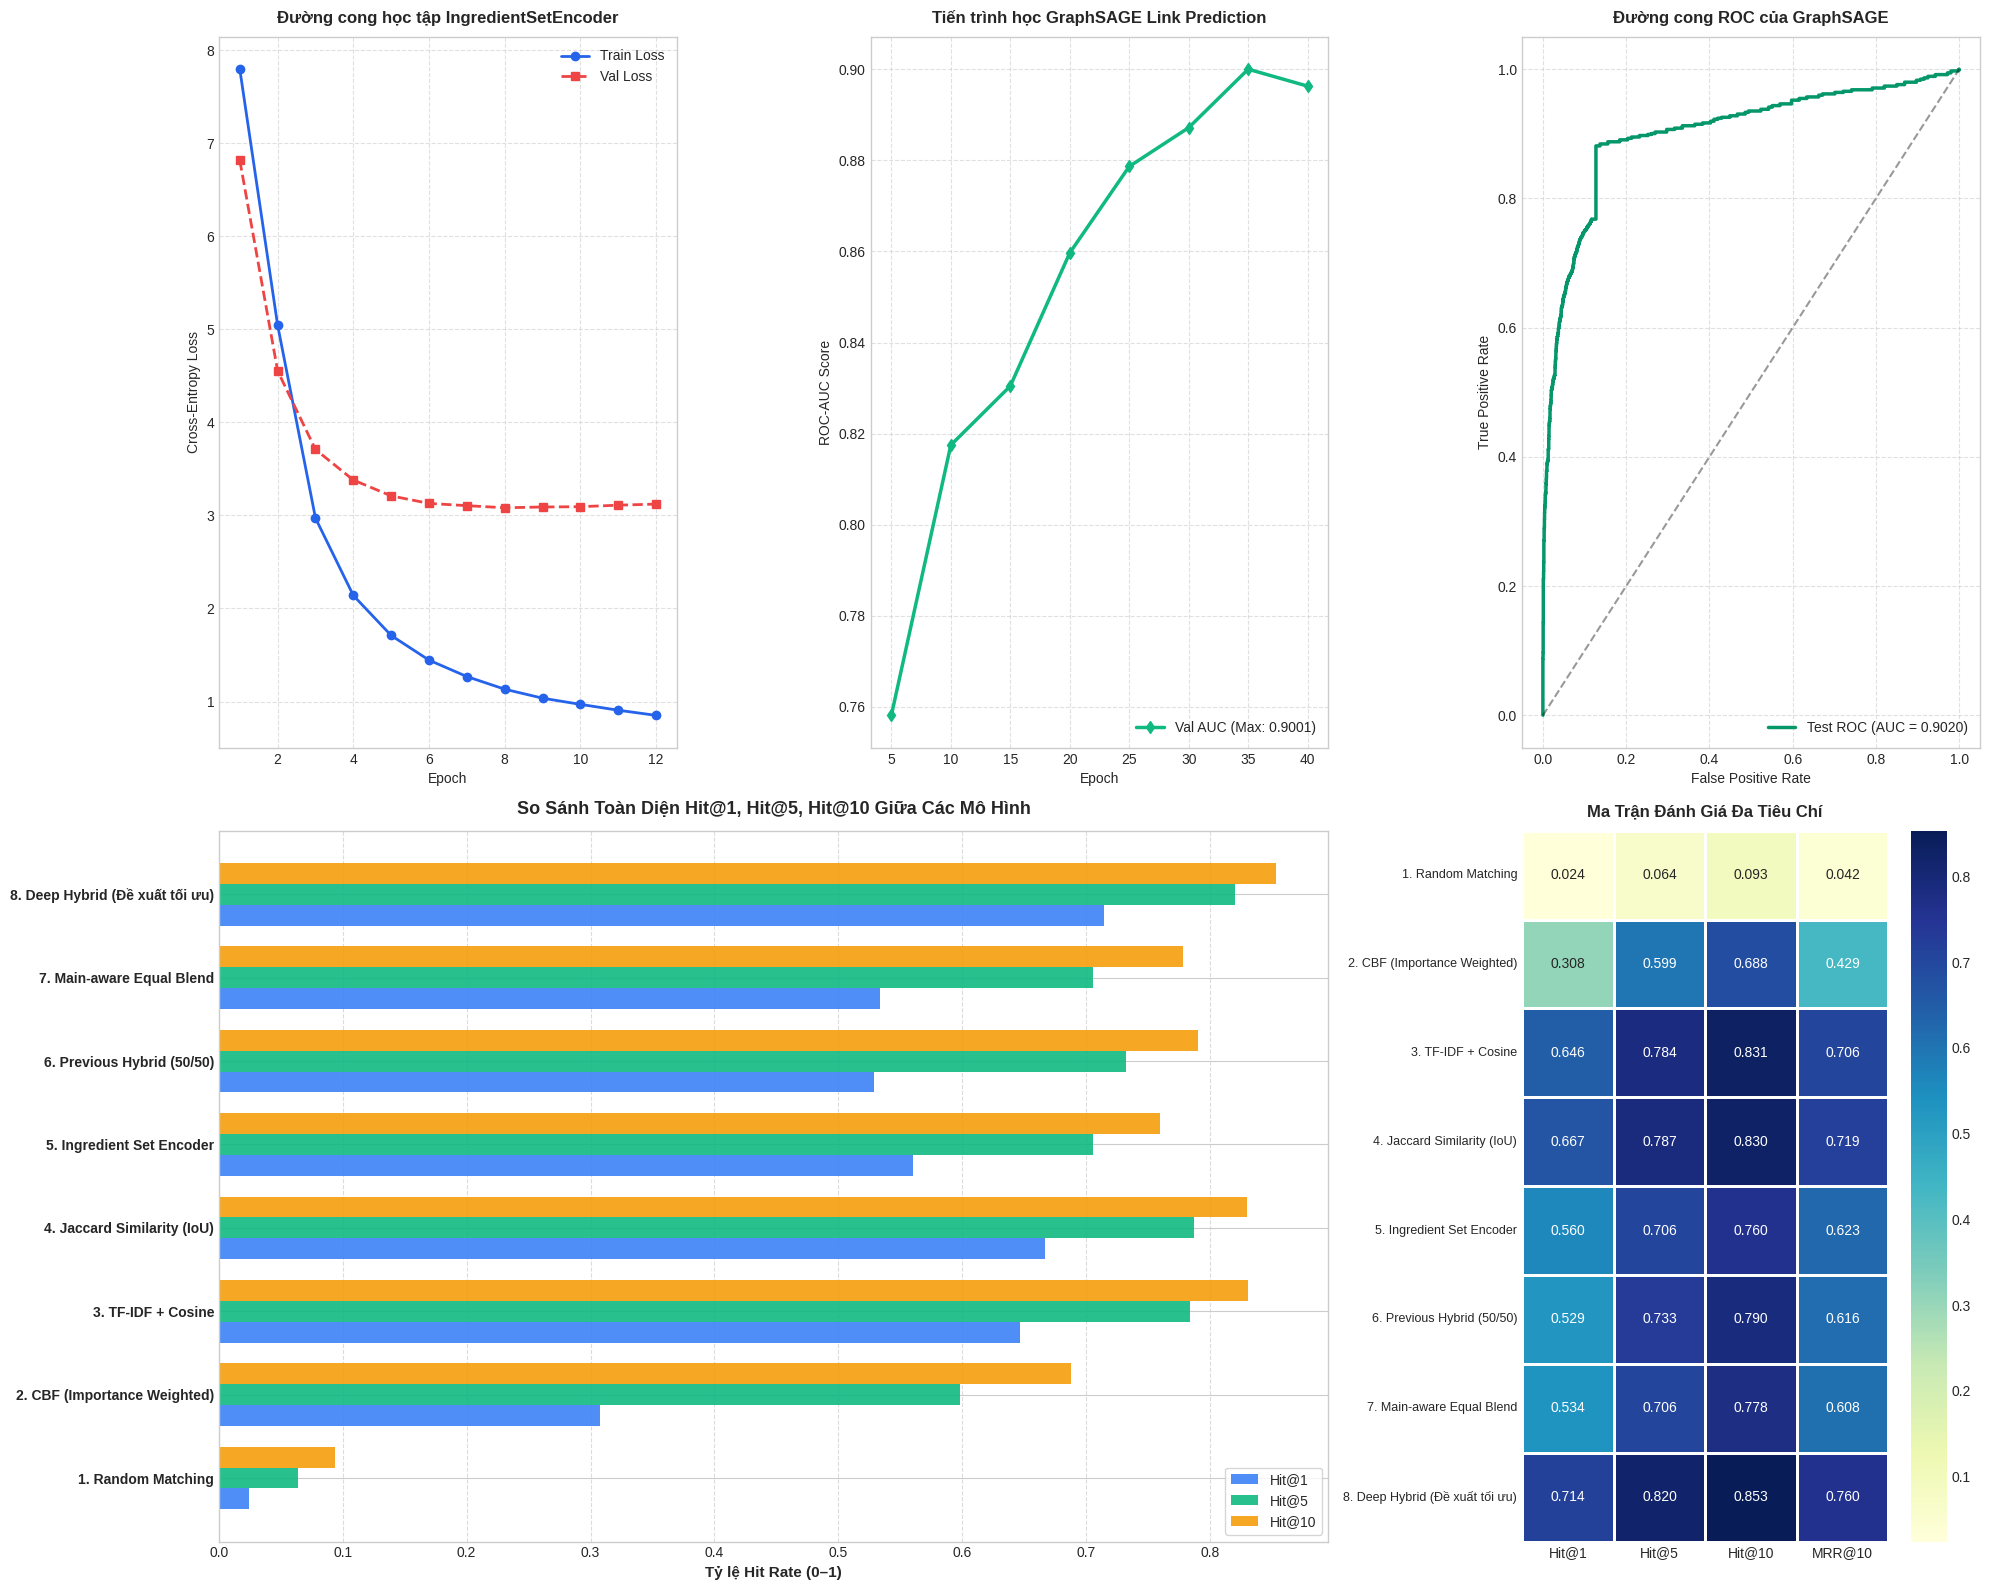

In [7]:
# Recommendation model comparison charts
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 10))
ax1 = plt.subplot(2, 2, 1)
epochs_range = range(1, len(train_loss_history) + 1)
ax1.plot(epochs_range, train_loss_history, 'o-', label='Train Loss')
ax1.plot(epochs_range, val_loss_history, 's--', label='Val Loss')
ax1.set_title('Ingredient Set Encoder'); ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss'); ax1.legend(); ax1.grid(True)
ax2 = plt.subplot(2, 2, 2)
models = list(df_comparison.index); x_pos = np.arange(len(models)); width = 0.25
ax2.barh(x_pos - width, df_comparison['Hit@1'], width, label='Hit@1')
ax2.barh(x_pos, df_comparison['Hit@5'], width, label='Hit@5')
ax2.barh(x_pos + width, df_comparison['Hit@10'], width, label='Hit@10')
ax2.set_yticks(x_pos); ax2.set_yticklabels(models, fontsize=9); ax2.set_xlabel('Hit Rate'); ax2.set_title('Recommendation Hit Rates'); ax2.legend(loc='lower right'); ax2.grid(True, axis='x')
ax3 = plt.subplot(2, 2, (3, 4))
criteria_matrix = df_comparison[['Hit@1', 'Hit@5', 'Hit@10', 'MRR']].copy().rename(columns={'MRR': 'MRR@10'})
sns.heatmap(criteria_matrix, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax3)
ax3.set_title('Recommendation model metrics'); ax3.set_yticklabels(criteria_matrix.index, rotation=0, fontsize=9)
plt.tight_layout(); chart_path = OUTPUT_DIR / 'model_comparison_charts.png'; plt.savefig(chart_path, dpi=300, bbox_inches='tight'); print(f'Saved chart: {chart_path}'); plt.show()

In [8]:
# Xây dựng đồ thị và đối chiếu luồng gợi ý với app.py.
from collections import defaultdict

kg = defaultdict(list); inv_kg = defaultdict(list)
for d in recipes:
    did = d['id']
    for ing_name, imp in d['ingredients'].items():
        kg[did].append({'rel': 'requires', 'target': ing_name, 'importance': imp})
        inv_kg[ing_name].append({'rel': 'required_by', 'target': did, 'importance': imp})
    if d['category']:
        kg[did].append({'rel': 'category', 'target': d['category']})
        inv_kg[d['category']].append({'rel': 'category_of', 'target': did})
recipe_idx_by_id = {d['id']: i for i, d in enumerate(recipes)}

def graph_candidates(ingredient_ids, category=None):
    candidates = set()
    for iid in ingredient_ids:
        for edge in inv_kg.get(keys[iid], []):
            if edge['target'] in recipe_idx_by_id:
                candidates.add(recipe_idx_by_id[edge['target']])
    if category:
        category_matches = {recipe_idx_by_id[e['target']] for e in inv_kg.get(category, [])
                            if e['target'] in recipe_idx_by_id}
        candidates &= category_matches
    return candidates

def graph_explanation(dish_idx, user_ing_ids):
    dish = recipes[dish_idx]
    user_keys = {keys[i] for i in user_ing_ids}
    matched, missing = [], []
    for edge in kg.get(dish['id'], []):
        if edge.get('rel') == 'requires':
            name = edge.get('target')
            item = {'name': names.get(name, name), 'importance': edge.get('importance', 1)}
            (matched if name in user_keys else missing).append(item)
    return {'matched': matched, 'missing': missing, 'category': dish.get('category')}

def recommend(ingredients, top_k=10, method='hybrid', category=None, assume_pantry=True):
    if isinstance(ingredients, str):
        raw_items = [s.strip() for s in ingredients.split(',') if s.strip()]
    else:
        raw_items = [str(s).strip() for s in ingredients if str(s).strip()]
    resolved = [synonym_to_canonical.get(normalize(s), normalize(s)) for s in raw_items]
    unknown = [raw_items[i] for i, key in enumerate(resolved) if key not in vocab]
    ids = sorted({vocab[key] for key in resolved if key in vocab})
    optional = set(DEFAULT_PANTRY) if assume_pantry else set()
    result = {'ready': [], 'needs_shopping': [], 'unknown': unknown,
              'query_resolved': [names.get(keys[i], keys[i]) for i in ids]}
    if not ids:
        return result

    x = torch.tensor([ids])
    deep, cbf, coverage, main, matched = features_batch(x)
    configs = {'hybrid': best_coeff, 'cbf': (0, 1, 0, 0),
               'encoder': (1, 0, 0, 0), 'main_aware': (0.25, 0.25, 0.25, 0.25)}
    coeff = configs.get(method, best_coeff)
    scores = sum(w * feature[0] for w, feature in zip(coeff, (deep, cbf, coverage, main)))
    candidates = graph_candidates(ids, category=category if category != 'all' else None)
    for idx in np.argsort(-scores):
        if idx not in candidates:
            continue
        dish = recipes[idx]
        have = set(ids)
        missing_keys = [k for k in dish['ingredients'] if vocab.get(k) not in have]
        missing_required = [k for k in missing_keys if k not in optional]
        explanation = graph_explanation(idx, ids)
        group = 'ready' if not missing_required else 'needs_shopping'
        max_imp = max(dish['ingredients'].values()) if dish['ingredients'] else 1.0
        result[group].append({
            'dish_id': dish['id'], 'dish': dish['name'],
            'score': round(float(scores[idx]), 4),
            'score_percent': int(min(100, max(0, float(scores[idx]) * 100))),
            'matched': [names.get(k, k) for k in dish['ingredients'] if vocab.get(k) in have],
            'missing_required': [names.get(k, k) for k in missing_required],
            'missing_optional': [names.get(k, k) for k in missing_keys if k in optional],
            'missing_main_provisional': [names.get(k, k) for k in missing_required
                                         if dish['ingredients'][k] == max_imp],
            'input_utilization': round(float(coverage[0, idx]) * 100, 1),
            'category': explanation.get('category', 'Khác'), 'kg_explanation': explanation,
            'url': dish.get('url'),
            'image_url': dish.get('image_url') or 'https://images.unsplash.com/photo-1546069901-ba9599a7e63c?auto=format&fit=crop&w=400&q=80'
        })
    result['needs_shopping'].sort(key=lambda item: (
        len(item['missing_main_provisional']), len(item['missing_required']), -item['score']))
    result['ready'] = result['ready'][:top_k]
    result['needs_shopping'] = result['needs_shopping'][:top_k]
    return result

sample_q = ['thịt heo', 'cà chua', 'hành tây']
res_test = recommend(sample_q, top_k=3, method='hybrid', assume_pantry=True)
print(f'\n=== GỢI Ý THỬ VỚI: {sample_q} ===')
for group in ('ready', 'needs_shopping'):
    print(group.upper() + ':')
    for result in res_test[group]:
        print(f"  - {result['dish']} (score: {result['score']}, tận dụng: {result['input_utilization']}%)")
print('Chưa nhận diện:', res_test['unknown'])


=== GỢI Ý THỬ VỚI: ['thịt heo', 'cà chua', 'hành tây'] ===
READY:
  - Thịt heo chiên tỏi ớt (score: 0.6249, tận dụng: 66.7%)
  - Nước ép cà chua không cần máy (score: 0.5512, tận dụng: 33.3%)
  - Thịt kho nước mắm (score: 0.3778, tận dụng: 33.3%)
NEEDS_SHOPPING:
  - Nước ép cà chua (score: 0.4817, tận dụng: 33.3%)
  - Nước ép cà chua chín (score: 0.4355, tận dụng: 33.3%)
  - Mứt cà chua (score: 0.4426, tận dụng: 33.3%)
Chưa nhận diện: []


In [9]:
# Xuất cả bộ kết quả của lần chạy hiện tại vào thư mục riêng.
print('=== XUẤT MÔ HÌNH VÀ KẾT QUẢ ===')
checkpoint = {
    'state_dict': model.state_dict(), 'vocab': vocab,
    'synonym_to_canonical': synonym_to_canonical, 'default_pantry': list(DEFAULT_PANTRY),
    'best_coeff': best_coeff, 'recipes': recipes, 'names': names, 'run_id': RUN_ID
}
torch.save(checkpoint, OUTPUT_DIR / 'ingredient_set_encoder.pt')
with (OUTPUT_DIR / 'knowledge_graph.json').open('w', encoding='utf-8') as f:
    json.dump({'kg': kg, 'names': names, 'run_id': RUN_ID,
               'categories': sorted({d['category'] for d in recipes if d['category']})},
              f, ensure_ascii=False)

# Lưu chính xác từng truy vấn đã chia, với mã nguyên liệu và vị trí công thức
# tương ứng với vocab/recipes trong checkpoint của cùng lần chạy.
split_export = {name: [{'ingredient_ids': list(query), 'recipe_index': int(label)}
                       for query, label in examples] for name, examples in splits.items()}
with (OUTPUT_DIR / 'splits.json').open('w', encoding='utf-8') as f:
    json.dump(split_export, f, ensure_ascii=False)

df_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', encoding='utf-8-sig')
test_names = {
    '1. Random Matching': 'Random',
    '2. CBF (Importance Weighted)': 'CBF',
    '3. TF-IDF + Cosine': 'TF-IDF Cosine',
    '4. Jaccard Similarity (IoU)': 'Jaccard Similarity',
    '5. Ingredient Set Encoder': 'Encoder',
    '6. Previous Hybrid (50/50)': 'Previous hybrid 50/50',
    '7. Main-aware Equal Blend': 'Main-aware Equal Blend',
    '8. Deep Hybrid (Đề xuất tối ưu)': 'Deep hybrid (validation selected)',
}
test_metrics = {}
for source_name, output_name in test_names.items():
    values = dict(results_dict[source_name])
    values['MRR@10'] = values['MRR']  # Giữ MRR để tương thích với bảng cũ.
    test_metrics[output_name] = values
val_selected = evaluate_features(val_features, val_labels, best_coeff)
val_selected['MRR@10'] = val_selected['MRR']
test_selected = test_metrics['Deep hybrid (validation selected)']
run_info = {
    'id': RUN_ID, 'seed': SEED, 'device': str(DEVICE),
    'data_file': DATA_PATH.name, 'data_sha256': sha256_file(DATA_PATH),
    'synonyms_file': SYN_PATH.name, 'synonyms_sha256': sha256_file(SYN_PATH),
    'splits_sha256': sha256_file(OUTPUT_DIR / 'splits.json'),
    'encoder_epochs_limit': ENCODER_EPOCHS,
    'batch_size': BATCH_SIZE, 'python': platform.python_version(),
    'torch': str(torch.__version__), 'numpy': np.__version__, 'pandas': pd.__version__,
    'mrr_definition': 'MRR@10; xếp ngoài 10 vị trí đầu được tính 0',
}
metrics = {
    'selected_weights': [float(value) for value in best_coeff],
    'validation_hit10': float(best_score), 'test': test_metrics,
    'split_sizes': {name: len(examples) for name, examples in splits.items()},
    'run': run_info,
}
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2, allow_nan=False)

export_names = ['ingredient_set_encoder.pt', 'knowledge_graph.json',
                'splits.json', 'model_comparison.csv', 'metrics.json', 'model_comparison_charts.png']
manifest = {'run': run_info, 'files_sha256': {name: sha256_file(OUTPUT_DIR / name)
                                               for name in export_names if (OUTPUT_DIR / name).is_file()}}
with (OUTPUT_DIR / 'run_manifest.json').open('w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2, allow_nan=False)
print(f'✓ Đã lưu bộ kết quả của lần chạy {RUN_ID}: {OUTPUT_DIR.resolve()}')
print('✓ metrics.json có MRR@10 cùng Hit@K từ chính lần chạy này.')

=== XUẤT MÔ HÌNH VÀ KẾT QUẢ ===
✓ Đã lưu bộ kết quả của lần chạy 20261124T044511397310Z: /kaggle/working/training_runs/20261124T044511397310Z
✓ metrics.json có MRR@10 cùng Hit@K từ chính lần chạy này.
Lưu ý: GNN chỉ được đánh giá dự đoán liên kết; web không dùng GraphSAGE để xếp hạng.
